In [11]:
import matplotlib.pyplot as plt
import numpy as np

from exoplanet_finder.data_preparation.detrend import flatten_lightcurve
from exoplanet_finder.data_preparation.folding import bin_curve, fold
from exoplanet_finder.data_preparation.transform_units import hours_to_days
from exoplanet_finder.data_preparation.transit_math import (
    orbit_window_bounds,
    transit_window_bounds,
)
from exoplanet_finder.download_data.download import get_lightcurve, load_from_api
from exoplanet_finder.paths import KOI_TABLE_PATH, LIGHT_CURVES_DIR
from exoplanet_finder.visualizations.graphs import plot_binned_curve

#Get data
query = (
    "select kepid, kepoi_name, kepler_name, koi_disposition, koi_fpflag_ss, "
    "koi_period, koi_time0bk, koi_duration, koi_depth from cumulative"
)
url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?"

table = load_from_api(url, query, KOI_TABLE_PATH)

In [12]:
#get usefull units
table["koi_duration_days"] = hours_to_days(table["koi_duration"])

In [13]:
#Get data about light curves
planet = table[table["koi_disposition"] == "CONFIRMED"].iloc[0]
eclipsing_binary = table[table["koi_fpflag_ss"] == 1].iloc[0]

light_curve_eclipsing_binary = get_lightcurve(eclipsing_binary["kepid"], LIGHT_CURVES_DIR)
light_curve_planet = get_lightcurve(planet["kepid"], LIGHT_CURVES_DIR)

In [14]:
#flatten
eclipsing_binary_kois = table[table["kepid"] == eclipsing_binary["kepid"]]

eclipsing_binary_flat = flatten_lightcurve(
    light_curve_eclipsing_binary,
    eclipsing_binary_kois["koi_period"],
    eclipsing_binary_kois["koi_time0bk"],
    eclipsing_binary_kois["koi_duration_days"],
)

planet_kois = table[table["kepid"] == planet["kepid"]]

planet_flat = flatten_lightcurve(
    light_curve_planet,
    planet_kois["koi_period"],
    planet_kois["koi_time0bk"],
    planet_kois["koi_duration_days"],
)

In [15]:
#Get numpy pole
eclipsing_binary_np_light_curve = np.column_stack([eclipsing_binary_flat.time.value, eclipsing_binary_flat.flux.value])

planet_np_light_curve = np.column_stack([planet_flat.time.value, planet_flat.flux.value])

In [16]:
#fold and bin function
eclipsing_binary_fold_light_curve = fold(eclipsing_binary_np_light_curve, eclipsing_binary["koi_period"], eclipsing_binary["koi_time0bk"])
eclipsing_binary_low, eclipsing_binary_high = transit_window_bounds(eclipsing_binary["koi_duration_days"], 1.5)
eclipsing_binary_bin_light_curve = bin_curve(eclipsing_binary_fold_light_curve, 50, eclipsing_binary_low, eclipsing_binary_high)

planet_fold_light_curve = fold(planet_np_light_curve, planet["koi_period"], planet["koi_time0bk"])
planet_low, planet_high = transit_window_bounds(planet["koi_duration_days"], 1.5)
planet_bin_light_curve = bin_curve(planet_fold_light_curve, 50, planet_low, planet_high)

In [17]:
#wide represantion
planet_low_wide, planet_high_wide = orbit_window_bounds(planet["koi_period"])
planet_bin_wide = bin_curve(planet_fold_light_curve, 200, planet_low_wide, planet_high_wide)

eclipsing_binary_low_wide, eclipsing_binary_high_wide = orbit_window_bounds(eclipsing_binary["koi_period"])
eclipsing_binary_bin_wide = bin_curve(eclipsing_binary_fold_light_curve, 200, eclipsing_binary_low_wide, eclipsing_binary_high_wide)

<Axes: title={'center': 'Eclipsing binary: whole orbit'}, xlabel='Time from transit center [hours]', ylabel='Flux change [ppm]'>

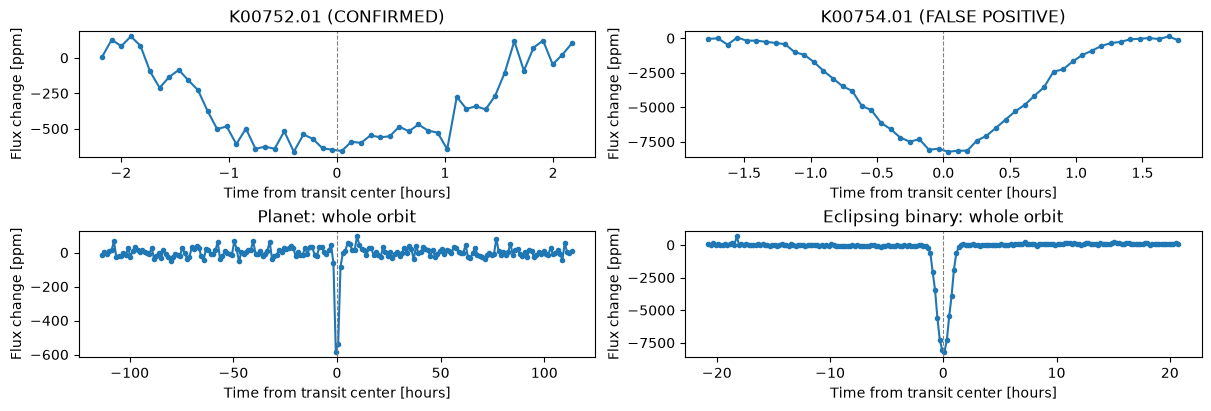

In [18]:
#Blit graph
fig, ((ax_top_left, ax_top_right), (ax_bottom_left, ax_bottom_right)) = plt.subplots(2, 2, figsize=(12, 4), layout="constrained")

plot_binned_curve(planet_bin_light_curve, planet_low, planet_high, f"{planet['kepoi_name']} ({planet['koi_disposition']})", ax=ax_top_left)
plot_binned_curve(eclipsing_binary_bin_light_curve, eclipsing_binary_low, eclipsing_binary_high, f"{eclipsing_binary['kepoi_name']} ({eclipsing_binary['koi_disposition']})", ax=ax_top_right)

plot_binned_curve(planet_bin_wide, planet_low_wide, planet_high_wide, "Planet: whole orbit", ax=ax_bottom_left)
plot_binned_curve(eclipsing_binary_bin_wide, eclipsing_binary_low_wide, eclipsing_binary_high_wide, "Eclipsing binary: whole orbit", ax=ax_bottom_right)